# Part 3 — Multivariate Gaussian

From TOML-MIRI *Linear Algebra for Data Science* — exploration exercises (sheet section [3.6]).

Topic exercises:

- **3.1** Build Σ from geometry
- **3.2** Generate correlated data from white noise
- **3.3** Recover the parameters
- **3.4** The precision matrix

This notebook implements exercises **3.1–3.4**. Each exercise keeps the sheet's own parts — **Task**, **Explore**, **Explain**, where the sheet has them — and every identity carries a one-line np.allclose check.

## Setup

Shared imports and helpers for the whole notebook. A covariance is stored as a small dictionary with the geometry (θ, λ1, λ2, μ), the rotation Q, the diagonal Λ and the matrix Σ = QΛQᵀ. The helpers turn that into samples, squared Mahalanobis radii and ellipse points, build the symmetric square root Σ¹ᐟ², read an arbitrary symmetric PD matrix into the same dictionary, and return sample moments, the principal frame and the angle between two directions.

In [1]:
import numpy as np
import scipy
import scipy.stats as stats

import matplotlib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

np.set_printoptions(precision=4, suppress=True)


def rotation_matrix(theta_deg):
    """Q = [[cos, -sin], [sin, cos]]; its columns are q1 and q2."""
    t = np.radians(theta_deg)
    return np.array([[np.cos(t), -np.sin(t)],
                     [np.sin(t),  np.cos(t)]])


def covariance_from_geometry(theta_deg, lam1, lam2, mu):
    """Sigma = Q Lambda Q^T with Q a rotation and Lambda = diag(lam1, lam2)."""
    Q = rotation_matrix(theta_deg)
    L = np.diag([float(lam1), float(lam2)])
    return dict(theta=float(theta_deg), lam1=float(lam1), lam2=float(lam2),
                mu=np.asarray(mu, dtype=float), Q=Q, L=L, Sigma=Q @ L @ Q.T)


def draw_gaussian(cov, N, seed=2027):
    """N samples from N(mu, Sigma), from a reproducible generator."""
    rng = np.random.default_rng(seed)
    return rng.multivariate_normal(cov["mu"], cov["Sigma"], size=N)


def mahalanobis_sq(X, mu, Sigma):
    """(x - mu)^T Sigma^{-1} (x - mu) for each row of X."""
    D = X - np.asarray(mu, dtype=float)
    return np.einsum("ij,jk,ik->i", D, np.linalg.inv(Sigma), D)


def ellipse_points(cov, c, n=361):
    """Points of (x - mu)^T Sigma^{-1} (x - mu) = c^2.

    With Sigma = Q Lambda Q^T the parametrisation
        x = mu + c Q Lambda^(1/2) (cos t, sin t)
    lies on the level set exactly.
    """
    t = np.linspace(0.0, 2.0 * np.pi, n)
    U = np.vstack([np.cos(t), np.sin(t)])
    return cov["mu"][:, None] + c * (cov["Q"] @ np.diag(np.sqrt([cov["lam1"], cov["lam2"]])) @ U)


def eigen_axis_segment(cov, c, i):
    """Segment through mu of length 2 c sqrt(lambda_i) along q_i, for c = 1, 2, 3."""
    q = cov["Q"][:, i]
    half = c * np.sqrt(cov["lam1"] if i == 0 else cov["lam2"])
    return cov["mu"][:, None] + np.outer([-half, half], q).T


def inside_fraction(r2, c):
    """Fraction of squared Mahalanobis radii inside the c-ellipse."""
    return float(np.mean(np.asarray(r2) <= c * c))


def sigma_sqrt(cov):
    """Symmetric square root Sigma^(1/2) = Q Lambda^(1/2) Q^T."""
    return cov["Q"] @ np.diag(np.sqrt([cov["lam1"], cov["lam2"]])) @ cov["Q"].T


def covariance_from_covariance(Sigma, mu):
    """Covariance dict from a symmetric PD matrix, via its eigendecomposition.

    numpy.linalg.eigh returns the eigenvalues in ascending order, so here
    lam1 <= lam2 and q1 is the eigenvector of the smaller eigenvalue. This is
    the convention used by Example 3.3 in the notes.
    """
    w, V = np.linalg.eigh(np.asarray(Sigma, dtype=float))
    return dict(theta=np.nan, lam1=float(w[0]), lam2=float(w[1]),
                mu=np.asarray(mu, dtype=float), Q=V, L=np.diag(w),
                Sigma=np.asarray(Sigma, dtype=float))


def sample_moments(X):
    """Sample mean and unbiased sample covariance (ddof=1)."""
    return X.mean(axis=0), np.cov(X.T, ddof=1)


def principal_frame(S):
    """Eigenvalues in descending order, orthonormal eigenvectors as columns."""
    w, V = np.linalg.eigh(S)
    order = np.argsort(w)[::-1]
    return w[order], V[:, order]


def angle_deg(u, v):
    """Angle in degrees between two lines (the sign of a direction is ignored)."""
    c = abs(float(np.dot(u, v))) / (float(np.linalg.norm(u)) * float(np.linalg.norm(v)))
    return float(np.degrees(np.arccos(np.clip(c, 0.0, 1.0))))


print("numpy", np.__version__, "| scipy", scipy.__version__)
print("covariance helpers ready")

numpy 2.5.4 | scipy 1.18.1
covariance helpers ready


## 3.1 — Build Σ from geometry

### Task

Build a 2×2 covariance

    Σ = Q Λ Qᵀ,    Q = [ cos θ  −sin θ ]    Λ = diag(λ1, λ2)
                        [ sin θ   cos θ ]

from a rotation angle θ and two variances λ1 and λ2, sample N points from N(μ, Σ), and
plot them together with the ellipses

    (x − μ)ᵀ Σ⁻¹ (x − μ) = c²,     c = 1, 2, 3,

and with the eigenvectors scaled by c √λi. In the figure the solid curves are the ellipses for
c = 1, 2, 3 and the dotted segments of matching colour are the eigenvectors scaled by c√λi.
The default is θ = 30°, λ1 = 4, λ2 = 1 and μ = (0.5, −0.3), sampled with N = 1000 points.

In [2]:
# --- Task: default covariance, samples and the numbers behind the figure --
THETA0, LAM1_0, LAM2_0 = 30.0, 4.0, 1.0
MU0 = np.array([0.5, -0.3])
N0 = 1000
SEED = 27

cov0 = covariance_from_geometry(THETA0, LAM1_0, LAM2_0, MU0)
Q0, L0, S0 = cov0["Q"], cov0["L"], cov0["Sigma"]
X0 = draw_gaussian(cov0, N0, seed=SEED)
r2_0 = mahalanobis_sq(X0, cov0["mu"], S0)

print("theta = %.1f deg,  lambda1 = %.2f,  lambda2 = %.2f" % (THETA0, LAM1_0, LAM2_0))
print("Q =\n", Q0)
print("Lambda =\n", L0)
print("Sigma = Q Lambda Q^T =\n", S0)
print("\neigenvalues of Sigma:        ", np.linalg.eigvalsh(S0))
print("eigenvectors of Sigma (Q):\n", Q0)
print("mu =", cov0["mu"], "   N =", N0)
print("sample mean =", np.round(X0.mean(axis=0), 4))
print("sample covariance (ddof=1) =\n", np.round(np.cov(X0.T, ddof=1), 4))

print("\n--- checks ---")
print("Q is orthogonal                        :", np.allclose(Q0.T @ Q0, np.eye(2)))
print("Sigma is symmetric                     :", np.allclose(S0, S0.T))
print("Sigma = Q diag(lam1, lam2) Q^T          :", np.allclose(S0, Q0 @ L0 @ Q0.T))
print("Sigma q_i = lambda_i q_i                :", np.allclose(S0 @ Q0, Q0 * [LAM1_0, LAM2_0]))
print("det(Sigma) = lambda1 lambda2            :", np.allclose(np.linalg.det(S0), LAM1_0 * LAM2_0))
print("Sigma^-1 = Q Lambda^-1 Q^T              :",
      np.allclose(np.linalg.inv(S0), Q0 @ np.diag([1.0 / LAM1_0, 1.0 / LAM2_0]) @ Q0.T))
for c in (1, 2, 3):
    P = ellipse_points(cov0, c)
    print("ellipse points satisfy r^2 = c^2 for c=%d:" % c,
          np.allclose(mahalanobis_sq(P.T, cov0["mu"], S0), c * c))
print("axis segments centred at mu and ending on the c-ellipse:",
      all(np.allclose(eigen_axis_segment(cov0, c, i).mean(axis=1), cov0["mu"]) and
          np.allclose(mahalanobis_sq(eigen_axis_segment(cov0, c, i).T, cov0["mu"], S0), c * c)
          for c in (1, 2, 3) for i in (0, 1)))
print("chi2_2(c^2) = 1 - exp(-c^2/2)             :",
      all(np.allclose(stats.chi2.cdf(c * c, 2), 1.0 - np.exp(-c * c / 2.0)) for c in (1, 2, 3)))

print("\nfraction inside each ellipse (true mu and Sigma), N = %d:" % N0)
print("%3s %8s %10s %12s" % ("c", "count", "fraction", "chi2_2(c^2)"))
for c in (1, 2, 3):
    print("%3d %8d %10.4f %12.4f"
          % (c, int(np.sum(r2_0 <= c * c)), inside_fraction(r2_0, c), stats.chi2.cdf(c * c, 2)))

theta = 30.0 deg,  lambda1 = 4.00,  lambda2 = 1.00
Q =
 [[ 0.866 -0.5  ]
 [ 0.5    0.866]]
Lambda =
 [[4. 0.]
 [0. 1.]]
Sigma = Q Lambda Q^T =
 [[3.25  1.299]
 [1.299 1.75 ]]

eigenvalues of Sigma:         [1. 4.]
eigenvectors of Sigma (Q):
 [[ 0.866 -0.5  ]
 [ 0.5    0.866]]
mu = [ 0.5 -0.3]    N = 1000
sample mean = [ 0.3844 -0.344 ]
sample covariance (ddof=1) =
 [[3.3443 1.418 ]
 [1.418  1.7675]]

--- checks ---
Q is orthogonal                        : True
Sigma is symmetric                     : True
Sigma = Q diag(lam1, lam2) Q^T          : True
Sigma q_i = lambda_i q_i                : True
det(Sigma) = lambda1 lambda2            : True
Sigma^-1 = Q Lambda^-1 Q^T              : True
ellipse points satisfy r^2 = c^2 for c=1: True
ellipse points satisfy r^2 = c^2 for c=2: True
ellipse points satisfy r^2 = c^2 for c=3: True
axis segments centred at mu and ending on the c-ellipse: True
chi2_2(c^2) = 1 - exp(-c^2/2)             : True

fraction inside each ellipse (true mu and Sigma)

In [3]:
# --- interactive figure: theta, lambda1 and lambda2 sliders ----------------
N_INTERACTIVE = 1000
C_VALUES = (1, 2, 3)
C_COLORS = {1: "#2ca02c", 2: "#ff7f0e", 3: "#d62728"}
RANGE_ND = 4.2


def axis_limits(cov):
    """Half-width of the square drawn around mu, large enough for c = 3."""
    return RANGE_ND * np.sqrt(max(cov["lam1"], cov["lam2"]))


def readout_text(cov, N, r2):
    inside = "   ".join("c=%d: %5.1f%%" % (c, 100.0 * inside_fraction(r2, c))
                       for c in C_VALUES)
    return ("N = %d   mu = (%+.2f, %+.2f)<br>"
            "theta = %+.1f deg   lambda1 = %.2f   lambda2 = %.2f<br>"
            "inside %s" % (N, cov["mu"][0], cov["mu"][1],
                           cov["theta"], cov["lam1"], cov["lam2"], inside))


def covariance_title(cov):
    return ("Sigma = Q Lambda Q^T   |   theta = %+.1f deg<br>"
            "eigenvalues lambda1 = %.2f, lambda2 = %.2f   |   det = %.3f"
            % (cov["theta"], cov["lam1"], cov["lam2"], cov["lam1"] * cov["lam2"]))


def make_frame(name, cov, X, r2):
    """One frame: sample cloud, three ellipses, their axis segments, centre and read-out."""
    data = [go.Scatter(x=X[:, 0], y=X[:, 1])]
    for c in C_VALUES:
        P = ellipse_points(cov, c)
        data.append(go.Scatter(x=P[0], y=P[1]))
    for c in C_VALUES:
        for i in (0, 1):
            A = eigen_axis_segment(cov, c, i)
            data.append(go.Scatter(x=A[0], y=A[1]))
    data.append(go.Scatter(x=[cov["mu"][0]], y=[cov["mu"][1]]))
    data.append(go.Scatter(text=[readout_text(cov, len(X), r2)]))
    half = axis_limits(cov)
    return go.Frame(
        name=name, data=data, traces=list(range(12)),
        layout=go.Layout(title_text=covariance_title(cov),
                         xaxis=dict(range=[cov["mu"][0] - half, cov["mu"][0] + half]),
                         yaxis=dict(range=[cov["mu"][1] - half, cov["mu"][1] + half])),
    )


def prepared_frame(name, theta, lam1, lam2):
    cov = covariance_from_geometry(theta, lam1, lam2, MU0)
    X = np.round(draw_gaussian(cov, N_INTERACTIVE, seed=SEED), 4)
    r2 = mahalanobis_sq(X, cov["mu"], cov["Sigma"])
    return make_frame(name, cov, X, r2)


fig = make_subplots(rows=1, cols=1)

# trace 0: sample cloud
fig.add_trace(go.Scatter(x=np.round(X0[:, 0], 4), y=np.round(X0[:, 1], 4),
                         mode="markers",
                         marker=dict(size=5, color="rgba(70,130,180,0.45)",
                                     line=dict(width=0.4, color="rgba(30,60,90,0.35)")),
                         name="N = %d samples" % N0, hoverinfo="skip"))

# traces 1-3: the three ellipses
for c in C_VALUES:
    P = ellipse_points(cov0, c)
    fig.add_trace(go.Scatter(x=np.round(P[0], 4), y=np.round(P[1], 4),
                             mode="lines", line=dict(color=C_COLORS[c], width=2.2),
                             name="ellipse c=%d" % c))

# traces 4-9: eigenvectors scaled by c sqrt(lambda_i)
for c in C_VALUES:
    for i in (0, 1):
        A = eigen_axis_segment(cov0, c, i)
        fig.add_trace(go.Scatter(x=np.round(A[0], 4), y=np.round(A[1], 4),
                                 mode="lines",
                                 line=dict(color=C_COLORS[c], width=1.1, dash="dot"),
                                 showlegend=False, hoverinfo="skip"))

# trace 10: centre mu
fig.add_trace(go.Scatter(x=[MU0[0]], y=[MU0[1]], mode="markers+text",
                         marker=dict(symbol="x", size=12, color="black",
                                     line=dict(width=2)),
                         text=["mu"], textposition="top right",
                         textfont=dict(size=11, color="black"),
                         name="mu", hoverinfo="skip"))

# trace 11: read-out
fig.add_trace(go.Scatter(x=[MU0[0] - axis_limits(cov0)], y=[MU0[1] + axis_limits(cov0)],
                         mode="text", text=[readout_text(cov0, N0, r2_0)],
                         textposition="top left",
                         textfont=dict(family="monospace", size=10),
                         showlegend=False, hoverinfo="skip"))

theta_vals = np.round(np.arange(-90.0, 90.001, 15.0), 10)
lam1_vals = np.round(np.arange(0.5, 4.0001, 0.5), 10)
lam2_vals = np.round(np.arange(0.5, 4.0001, 0.5), 10)

theta_names = ["theta=%+.1f" % v for v in theta_vals]
lam1_names = ["lam1=%.2f" % v for v in lam1_vals]
lam2_names = ["lam2=%.2f" % v for v in lam2_vals]

frames = ([prepared_frame(nm, v, LAM1_0, LAM2_0) for nm, v in zip(theta_names, theta_vals)]
          + [prepared_frame(nm, THETA0, v, LAM2_0) for nm, v in zip(lam1_names, lam1_vals)]
          + [prepared_frame(nm, THETA0, LAM1_0, v) for nm, v in zip(lam2_names, lam2_vals)])

presets = [
    ("preset:default", "default", 30.0, 4.0, 1.0),
    ("preset:isotropic", "lambda1 = lambda2", 30.0, 2.0, 2.0),
    ("preset:aligned", "theta = 0", 0.0, 4.0, 1.0),
    ("preset:narrow", "narrow", 30.0, 4.0, 0.5),
]
frames += [prepared_frame(name, t, l1, l2) for name, label, t, l1, l2 in presets]
fig.frames = frames


def animate_step(name):
    return dict(method="animate", label=name.split("=")[-1],
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])


def slider_for(prefix, names, base_value, values):
    steps = [animate_step(nm) for nm in names]
    active = int(np.argmin(np.abs(np.asarray(values) - base_value)))
    return dict(active=active, currentvalue=dict(prefix=prefix + " = ", font=dict(size=12)),
                steps=steps, pad=dict(t=25))


buttons = [dict(label=label, method="animate",
                args=[[name], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True),
                                   transition=dict(duration=0))])
           for name, label, t, l1, l2 in presets]

half0 = axis_limits(cov0)
fig.update_layout(
    height=720, width=820, showlegend=True,
    legend=dict(x=1.02, xanchor="left", y=1.0, yanchor="top", font=dict(size=10)),
    title_text=covariance_title(cov0),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.13,
                      xanchor="left", yanchor="bottom", showactive=True, buttons=buttons)],
    sliders=[dict(slider_for("theta", theta_names, THETA0, theta_vals),
                  x=0.02, len=0.30, y=-0.16),
             dict(slider_for("lambda1", lam1_names, LAM1_0, lam1_vals),
                  x=0.36, len=0.30, y=-0.16),
             dict(slider_for("lambda2", lam2_names, LAM2_0, lam2_vals),
                  x=0.70, len=0.30, y=-0.16)],
    margin=dict(l=20, r=190, t=145, b=100),
)
fig.update_xaxes(range=[MU0[0] - half0, MU0[0] + half0], title_text="x1")
fig.update_yaxes(range=[MU0[1] - half0, MU0[1] + half0], title_text="x2",
                 scaleanchor="x", scaleratio=1)
print("figure payload: %d frames, %.0f kB of JSON" % (len(fig.frames), len(fig.to_json()) / 1024))
fig.show()

figure payload: 33 frames, 1875 kB of JSON


### Explore

Sample sizes N = 100, 1,000 and 100,000, and the isotropic case λ1 = λ2. The three panels below use the default geometry (θ = 30°, λ1 = 4, λ2 = 1, μ = (0.5, −0.3)) and the same ellipse levels c = 1, 2, 3.

sample statistics and inside fractions (true mu and Sigma), default geometry
N               mean x1        mean x2   p(c=1)     chi2   p(c=2)     chi2   p(c=3)     chi2
100             +0.3247        -0.1933   0.4000   0.3935   0.8600   0.8647   0.9900   0.9889
1000            +0.3844        -0.3440   0.3960   0.3935   0.8640   0.8647   0.9890   0.9889
100000          +0.4948        -0.3002   0.3934   0.3935   0.8645   0.8647   0.9889   0.9889

counts and binomial standard errors of the inside fraction:
N          c    count   fraction     chi2_2    std err        z
100        1       40     0.4000     0.3935    0.04885   +0.134
100        2       86     0.8600     0.8647    0.03421   -0.136
100        3       99     0.9900     0.9889    0.01048   +0.106
1000       1      396     0.3960     0.3935    0.01545   +0.164
1000       2      864     0.8640     0.8647    0.01082   -0.061
1000       3      989     0.9890     0.9889    0.00331   +0.033
100000     1    39343     0.3934     0.393

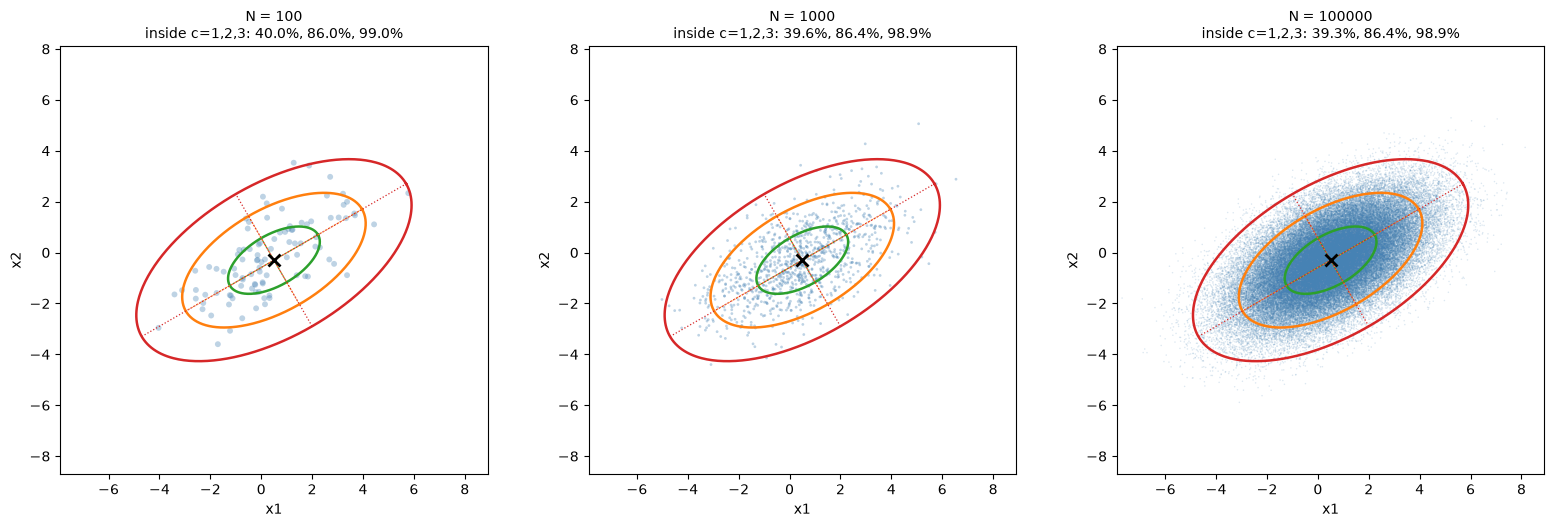

In [4]:
# --- Explore: the three sample sizes -------------------------------------
N_VALUES = (100, 1000, 100000)
SEEDS = {100: 79, 1000: SEED, 100000: 17}
samples = {}

print("sample statistics and inside fractions (true mu and Sigma), default geometry")
print("%-8s %14s %14s %8s %8s %8s %8s %8s %8s"
      % ("N", "mean x1", "mean x2", "p(c=1)", "chi2", "p(c=2)", "chi2", "p(c=3)", "chi2"))
for N in N_VALUES:
    X = draw_gaussian(cov0, N, seed=SEEDS[N])
    r2 = mahalanobis_sq(X, cov0["mu"], cov0["Sigma"])
    samples[N] = (X, r2)
    print("%-8d %+14.4f %+14.4f %8.4f %8.4f %8.4f %8.4f %8.4f %8.4f"
          % (N, X[:, 0].mean(), X[:, 1].mean(),
             inside_fraction(r2, 1), stats.chi2.cdf(1, 2),
             inside_fraction(r2, 2), stats.chi2.cdf(4, 2),
             inside_fraction(r2, 3), stats.chi2.cdf(9, 2)))

print("\ncounts and binomial standard errors of the inside fraction:")
print("%-8s %3s %8s %10s %10s %10s %8s"
      % ("N", "c", "count", "fraction", "chi2_2", "std err", "z"))
for N in N_VALUES:
    _, r2 = samples[N]
    for c in C_VALUES:
        phat = inside_fraction(r2, c)
        p = stats.chi2.cdf(c * c, 2)
        se = np.sqrt(p * (1.0 - p) / N)
        print("%-8d %3d %8d %10.4f %10.4f %10.5f %+8.3f"
              % (N, c, int(np.sum(r2 <= c * c)), phat, p, se, (phat - p) / se))

print("\nsmallest and largest squared radius in each sample:")
for N in N_VALUES:
    _, r2 = samples[N]
    print("N = %-7d  r^2 in [%.3f, %.3f],  median %.3f"
          % (N, r2.min(), r2.max(), np.median(r2)))

ks = stats.kstest(samples[100000][1], "chi2", args=(2,))
print("\nKolmogorov-Smirnov check of r^2 against chi2_2 (N = 100000):")
print("  statistic = %.5f, p-value = %.4f" % (ks.statistic, ks.pvalue))
print("  theoretical median of chi2_2 = 2 ln 2 = %.4f, sample median = %.4f"
      % (2.0 * np.log(2.0), np.median(samples[100000][1])))


# --- the three samples as panels ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.1))
for ax, N in zip(axes, N_VALUES):
    X, r2 = samples[N]
    half = axis_limits(cov0)
    ax.scatter(X[:, 0], X[:, 1], s=18 if N == 100 else (4 if N == 1000 else 1.2),
               color="steelblue", alpha=0.35 if N < 100000 else 0.18,
               edgecolor="none", rasterized=(N == 100000))
    for c in C_VALUES:
        P = ellipse_points(cov0, c)
        ax.plot(P[0], P[1], color=C_COLORS[c], lw=1.8)
        for i in (0, 1):
            A = eigen_axis_segment(cov0, c, i)
            ax.plot(A[0], A[1], color=C_COLORS[c], lw=0.9, ls=":")
    ax.plot([MU0[0]], [MU0[1]], "x", color="black", ms=8, mew=2)
    ax.set_xlim(MU0[0] - half, MU0[0] + half)
    ax.set_ylim(MU0[1] - half, MU0[1] + half)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("N = %d\ninside c=1,2,3: %.1f%%, %.1f%%, %.1f%%"
                 % (N, 100 * inside_fraction(r2, 1), 100 * inside_fraction(r2, 2),
                    100 * inside_fraction(r2, 3)), fontsize=10)
fig.tight_layout()
plt.show()

Sigma(theta=30, lam1=lam2=2) =
 [[ 2. -0.]
 [-0.  2.]]
Sigma(theta=75, lam1=lam2=2) =
 [[ 2. -0.]
 [-0.  2.]]
the two Sigmas are equal              : True
both equal lambda I                   : True
circle radii c sqrt(lambda) for c=1,2,3: [1.4142 2.8284 4.2426]
(1, 0) is an eigenvector              : True
(0, 1) is an eigenvector              : True
Sigma u = 2u for 200 random unit u    : True
ellipse points still satisfy r^2 = c^2: True

inside fractions for the three panels, N = 1000:
case                        c=1      c=2      c=3
anisotropic default      0.3960   0.8640   0.9890
isotropic theta=30       0.3960   0.8640   0.9890
isotropic theta=75       0.3960   0.8640   0.9890


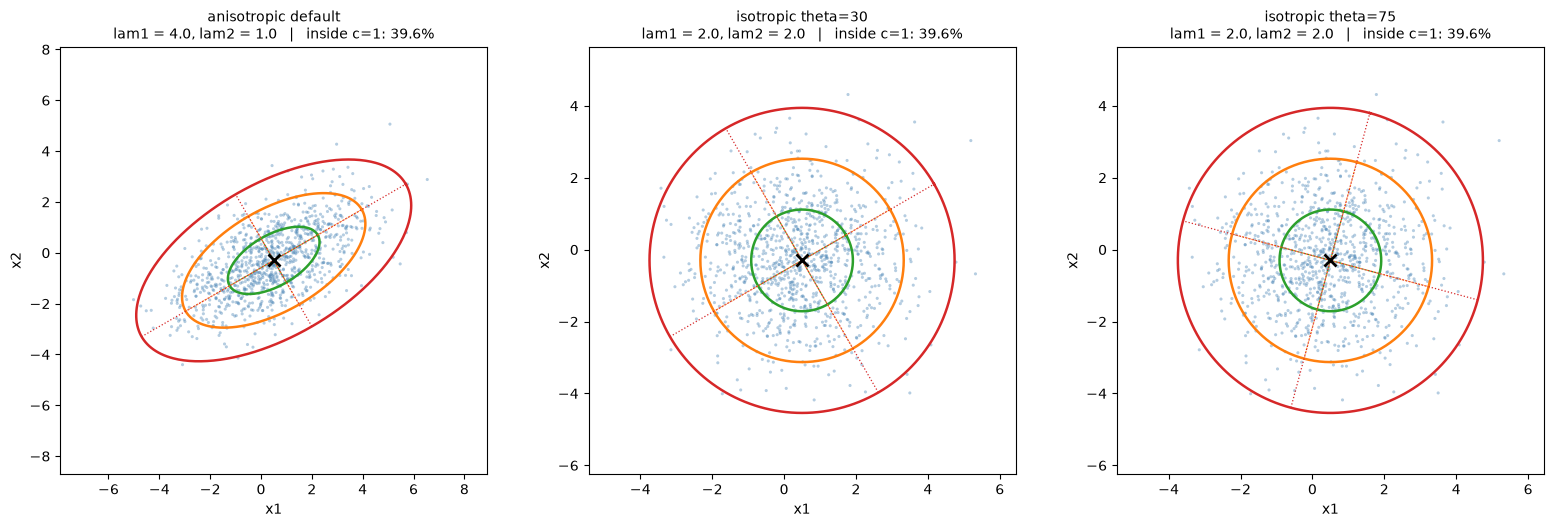

In [5]:
# --- Explore: lambda1 = lambda2 makes the ellipses circles ----------------
iso_a = covariance_from_geometry(30.0, 2.0, 2.0, MU0)
iso_b = covariance_from_geometry(75.0, 2.0, 2.0, MU0)
print("Sigma(theta=30, lam1=lam2=2) =\n", np.round(iso_a["Sigma"], 6))
print("Sigma(theta=75, lam1=lam2=2) =\n", np.round(iso_b["Sigma"], 6))
print("the two Sigmas are equal              :", np.allclose(iso_a["Sigma"], iso_b["Sigma"]))
print("both equal lambda I                   :", np.allclose(iso_a["Sigma"], 2.0 * np.eye(2)))
print("circle radii c sqrt(lambda) for c=1,2,3:",
      np.round([c * np.sqrt(2.0) for c in C_VALUES], 4))

rng = np.random.default_rng(7)
U = rng.standard_normal((2, 200))
U /= np.linalg.norm(U, axis=0)
print("(1, 0) is an eigenvector              :",
      np.allclose(iso_a["Sigma"] @ np.array([1.0, 0.0]), 2.0 * np.array([1.0, 0.0])))
print("(0, 1) is an eigenvector              :",
      np.allclose(iso_a["Sigma"] @ np.array([0.0, 1.0]), 2.0 * np.array([0.0, 1.0])))
print("Sigma u = 2u for 200 random unit u    :", np.allclose(iso_a["Sigma"] @ U, 2.0 * U))
print("ellipse points still satisfy r^2 = c^2:",
      all(np.allclose(mahalanobis_sq(ellipse_points(iso_a, c).T, iso_a["mu"], iso_a["Sigma"]),
                      c * c) for c in C_VALUES))

iso_cases = [
    ("anisotropic default", 30.0, 4.0, 1.0),
    ("isotropic theta=30", 30.0, 2.0, 2.0),
    ("isotropic theta=75", 75.0, 2.0, 2.0),
]
print("\ninside fractions for the three panels, N = 1000:")
print("%-22s %8s %8s %8s" % ("case", "c=1", "c=2", "c=3"))
for label, theta, lam1, lam2 in iso_cases:
    cov = covariance_from_geometry(theta, lam1, lam2, MU0)
    X = draw_gaussian(cov, 1000, seed=SEED)
    r2 = mahalanobis_sq(X, cov["mu"], cov["Sigma"])
    print("%-22s %8.4f %8.4f %8.4f"
          % (label, inside_fraction(r2, 1), inside_fraction(r2, 2), inside_fraction(r2, 3)))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.1))
for ax, (label, theta, lam1, lam2) in zip(axes, iso_cases):
    cov = covariance_from_geometry(theta, lam1, lam2, MU0)
    X = draw_gaussian(cov, 1000, seed=SEED)
    r2 = mahalanobis_sq(X, cov["mu"], cov["Sigma"])
    half = axis_limits(cov)
    ax.scatter(X[:, 0], X[:, 1], s=5, color="steelblue", alpha=0.40, edgecolor="none")
    for c in C_VALUES:
        P = ellipse_points(cov, c)
        ax.plot(P[0], P[1], color=C_COLORS[c], lw=1.8)
        for i in (0, 1):
            A = eigen_axis_segment(cov, c, i)
            ax.plot(A[0], A[1], color=C_COLORS[c], lw=0.9, ls=":")
    ax.plot([MU0[0]], [MU0[1]], "x", color="black", ms=8, mew=2)
    ax.set_xlim(MU0[0] - half, MU0[0] + half)
    ax.set_ylim(MU0[1] - half, MU0[1] + half)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("%s\nlam1 = %.1f, lam2 = %.1f   |   inside c=1: %.1f%%"
                 % (label, lam1, lam2, 100 * inside_fraction(r2, 1)), fontsize=10)
fig.tight_layout()
plt.show()

### Explain

**What fraction falls inside each ellipse?**

For x ~ N(μ, Σ) the quadratic form in the ellipse definition is the squared Mahalanobis distance

    r² = (x − μ)ᵀ Σ⁻¹ (x − μ).

Write Σ = Σ¹ᐟ² Σ¹ᐟ², for instance Σ¹ᐟ² = Q Λ¹ᐟ² Qᵀ, and set z = Σ⁻¹ᐟ²(x − μ). Then z ~ N(0, I₂) and

    r² = zᵀ z = z₁² + z₂².

The two components z₁ and z₂ are independent standard normal variables, so r² is the sum of two
independent squared standard normals — a χ² random variable with 2 degrees of freedom. The fraction
of the cloud inside the ellipse r² = c² is therefore

    P(r² ≤ c²) = F_χ²₂(c²) = 1 − exp(−c²/2),

where the last equality is the closed form of the χ²₂ CDF. The three values are

    c = 1: 1 − e^(−0.5) = 0.3935    (39.35%)
    c = 2: 1 − e^(−2)   = 0.8647    (86.47%)
    c = 3: 1 − e^(−4.5) = 0.9889    (98.89%).

These contours are not the one-dimensional 68%, 95%, 99.7% intervals; those numbers belong to a
single normal coordinate. In two dimensions the first contour already contains only about 39% of the
mass, because the probability is spread over the whole plane.

The run reproduces this. For the N = 1000 sample of the Task the counts are 396, 864 and 989,
i.e. 39.60%, 86.40% and 98.90%, against the χ²₂ values 39.35%, 86.47% and 98.89%. For N = 100,000 the
empirical fractions are 39.343%, 86.446% and 98.895%, with binomial standard errors 0.154%, 0.108%
and 0.033%; every difference is within one standard error. The N = 100 sample is much noisier at
40%, 86% and 99%, within one standard error (z = +0.13, −0.14 and +0.11). The Kolmogorov–Smirnov
comparison of the 100,000 squared radii with the χ²₂ distribution gives statistic 0.00302 and
p-value 0.3194, and the sample median 1.3918 matches the theoretical median 2 ln 2 = 1.3863. The
three Explore panels show the same numbers: the cloud fills each drawn contour in the χ²₂ proportion.

The fraction does not depend on θ, λ1, λ2 or μ. The Mahalanobis distance removes exactly the geometry
of Σ: rotating the cloud and stretching its two axes changes where the points lie but not the value r²
attached to each point, so the inside counts are unchanged. The parameters change only the shape and
orientation of the drawn ellipses.

**When λ1 = λ2.**

If λ1 = λ2 = λ, then Λ = λI and

    Σ = Q (λI) Qᵀ = λI.

The rotation cancels, so Σ is the same for every θ: the run shows Σ(30°, 2, 2) = Σ(75°, 2, 2) = 2I.
The level sets (x − μ)ᵀΣ⁻¹(x − μ) = c² become

    ‖x − μ‖² = λ c²,

which are circles of radius c√λ, not ellipses. Every direction is an eigen-direction — any unit vector u
satisfies Σu = λu — so q1 and q2 are no longer unique; the run checks that (1, 0), (0, 1) and 200 random
unit vectors are all eigenvectors with the same eigenvalue. Changing θ leaves the distribution and the
contours unchanged, and the eigenvector segments in the figure no longer mark a preferred direction.
The χ²₂ fractions stay the same, because the same Mahalanobis radius still has a χ²₂ distribution; only
the contours have lost their orientation.

## 3.2 — Generate correlated data from white noise

### Task

Sample z ~ N(0, I), apply the transformation

    x = μ + Q Λ¹ᐟ² z,        Cov(x) = Q Λ¹ᐟ² I Λ¹ᐟ² Qᵀ = Σ,

and compare the result with `np.random.multivariate_normal`. The geometry is the default of 3.1
(θ = 30°, λ1 = 4, λ2 = 1, μ = (0.5, −0.3)) and both generators use N = 1000 points. The four panels read
the symmetric square root Σ¹ᐟ² = QΛ¹ᐟ²Qᵀ as rotate (Qᵀ), stretch (Λ¹ᐟ²) and rotate back (Q); because Qᵀz is
again standard normal, that picture and the one-step recipe x = μ + QΛ¹ᐟ²z describe the same distribution.

In [6]:
# --- Task: white noise, the linear map, and the comparison with numpy ------
N32 = 1000
SEED32 = 27
rng = np.random.default_rng(SEED32)

Z = rng.standard_normal((N32, 2))                               # z ~ N(0, I)
Lsqrt = np.diag(np.sqrt([cov0["lam1"], cov0["lam2"]]))
A = cov0["Q"] @ Lsqrt                                           # Q Lambda^(1/2)
X_noise = cov0["mu"] + Z @ A.T                                  # mu + Q Lambda^(1/2) z
X_mvn = rng.multivariate_normal(cov0["mu"], cov0["Sigma"], size=N32)

# symmetric-square-root reading: Q^T, then Lambda^(1/2), then Q
Z_rot = Z @ cov0["Q"]                                           # (Q^T z)
Z_str = Z_rot * np.sqrt([cov0["lam1"], cov0["lam2"]])          # Lambda^(1/2) Q^T z
Z_back = Z_str @ cov0["Q"].T                                    # Q Lambda^(1/2) Q^T z

print("--- the map ---")
print("A = Q Lambda^(1/2) =\n", np.round(A, 4))
print("columns of A are q_i sqrt(lambda_i)      :",
      np.allclose(A, cov0["Q"] * np.sqrt([cov0["lam1"], cov0["lam2"]])))
print("A A^T = Sigma (exact)                    :", np.allclose(A @ A.T, cov0["Sigma"]))
print("Cov(Q^T z) = Q^T I Q = I (exact)         :",
      np.allclose(cov0["Q"].T @ np.eye(2) @ cov0["Q"], np.eye(2)))
print("Cov(Lambda^(1/2) Q^T z) = Lambda (exact) :", np.allclose(Lsqrt @ np.eye(2) @ Lsqrt, cov0["L"]))
print("Cov(Q Lambda^(1/2) Q^T z) = Sigma (exact):",
      np.allclose(cov0["Q"] @ Lsqrt @ np.eye(2) @ Lsqrt @ cov0["Q"].T, cov0["Sigma"]))

print("\n--- negative control: stretch by Lambda instead of Lambda^(1/2) ---")
A_wrong = cov0["Q"] @ cov0["L"]
print("Cov(Q Lambda z) = Q Lambda^2 Q^T =\n", np.round(A_wrong @ A_wrong.T, 4))
print("equals Sigma                             :", np.allclose(A_wrong @ A_wrong.T, cov0["Sigma"]),
      "  (negative control: False, because Lambda gives eigenvalues lambda_i^2, not lambda_i)")
print("its eigenvalues are lambda_i^2           :",
      np.allclose(np.sort(np.linalg.eigvalsh(A_wrong @ A_wrong.T)),
                  np.sort(np.array([cov0["lam1"], cov0["lam2"]]) ** 2)))

print("\n--- the two recipes, N = %d ---" % N32)
print("sample covariance of z (target I)        :\n", np.round(np.cov(Z.T, ddof=1), 4))
print("x = mu + Q Lambda^(1/2) z, sample cov    :\n", np.round(np.cov(X_noise.T, ddof=1), 4))
print("x = mu + Sigma^(1/2) z, sample cov       :\n", np.round(np.cov(Z_back.T, ddof=1), 4))
print("np.random.multivariate_normal, sample cov:\n", np.round(np.cov(X_mvn.T, ddof=1), 4))
print("Sigma                                    :\n", np.round(cov0["Sigma"], 4))
print("sample correlation of the white-noise map: %.4f   (theoretical %.4f)"
      % (np.corrcoef(X_noise.T)[0, 1],
         cov0["Sigma"][0, 1] / np.sqrt(cov0["Sigma"][0, 0] * cov0["Sigma"][1, 1])))

print("\n--- large sample, N = 200000: both recipes and numpy agree with Sigma ---")
N_BIG32 = 200000
rb = np.random.default_rng(SEED32 + 1)
Zb = rb.standard_normal((N_BIG32, 2))
Xb_noise = cov0["mu"] + Zb @ A.T
Xb_sqrt = cov0["mu"] + Zb @ sigma_sqrt(cov0).T
Xb_mvn = rb.multivariate_normal(cov0["mu"], cov0["Sigma"], size=N_BIG32)
for label, Xb in (("mu + Q Lambda^(1/2) z", Xb_noise),
                  ("mu + Sigma^(1/2) z", Xb_sqrt),
                  ("numpy mvn", Xb_mvn)):
    print("%-24s max|S - Sigma| = %.5f" % (label, np.abs(np.cov(Xb.T, ddof=1) - cov0["Sigma"]).max()))
print("all three within 0.05 of Sigma           :",
      all(np.allclose(np.cov(Xb.T, ddof=1), cov0["Sigma"], atol=0.05)
          for Xb in (Xb_noise, Xb_sqrt, Xb_mvn)))

print("\n--- distribution comparison, N = %d ---" % N32)
for j in range(2):
    ks = stats.ks_2samp(X_noise[:, j], X_mvn[:, j])
    print("coordinate %d: two-sample KS statistic = %.4f, p-value = %.4f"
          % (j + 1, ks.statistic, ks.pvalue))
r2_noise = mahalanobis_sq(X_noise, cov0["mu"], cov0["Sigma"])
r2_mvn = mahalanobis_sq(X_mvn, cov0["mu"], cov0["Sigma"])
ks_r = stats.ks_2samp(r2_noise, r2_mvn)
ks_chi = stats.kstest(r2_noise, "chi2", args=(2,))
print("Mahalanobis r^2: two-sample KS = %.4f, p-value = %.4f" % (ks_r.statistic, ks_r.pvalue))
print("r^2 of the white-noise map vs chi2_2: KS = %.4f, p-value = %.4f"
      % (ks_chi.statistic, ks_chi.pvalue))

--- the map ---
A = Q Lambda^(1/2) =
 [[ 1.7321 -0.5   ]
 [ 1.      0.866 ]]
columns of A are q_i sqrt(lambda_i)      : True
A A^T = Sigma (exact)                    : True
Cov(Q^T z) = Q^T I Q = I (exact)         : True
Cov(Lambda^(1/2) Q^T z) = Lambda (exact) : True
Cov(Q Lambda^(1/2) Q^T z) = Sigma (exact): True

--- negative control: stretch by Lambda instead of Lambda^(1/2) ---
Cov(Q Lambda z) = Q Lambda^2 Q^T =
 [[12.25    6.4952]
 [ 6.4952  4.75  ]]
equals Sigma                             : False   (negative control: False, because Lambda gives eigenvalues lambda_i^2, not lambda_i)
its eigenvalues are lambda_i^2           : True

--- the two recipes, N = 1000 ---
sample covariance of z (target I)        :
 [[ 1.0445 -0.0131]
 [-0.0131  0.9336]]
x = mu + Q Lambda^(1/2) z, sample cov    :
 [[3.3898 1.3918]
 [1.3918 1.722 ]]
x = mu + Sigma^(1/2) z, sample cov       :
 [[3.3541 1.2657]
 [1.2657 1.6405]]
np.random.multivariate_normal, sample cov:
 [[3.4098 1.4945]
 [1.4945 1.8352]]


both figures drawn


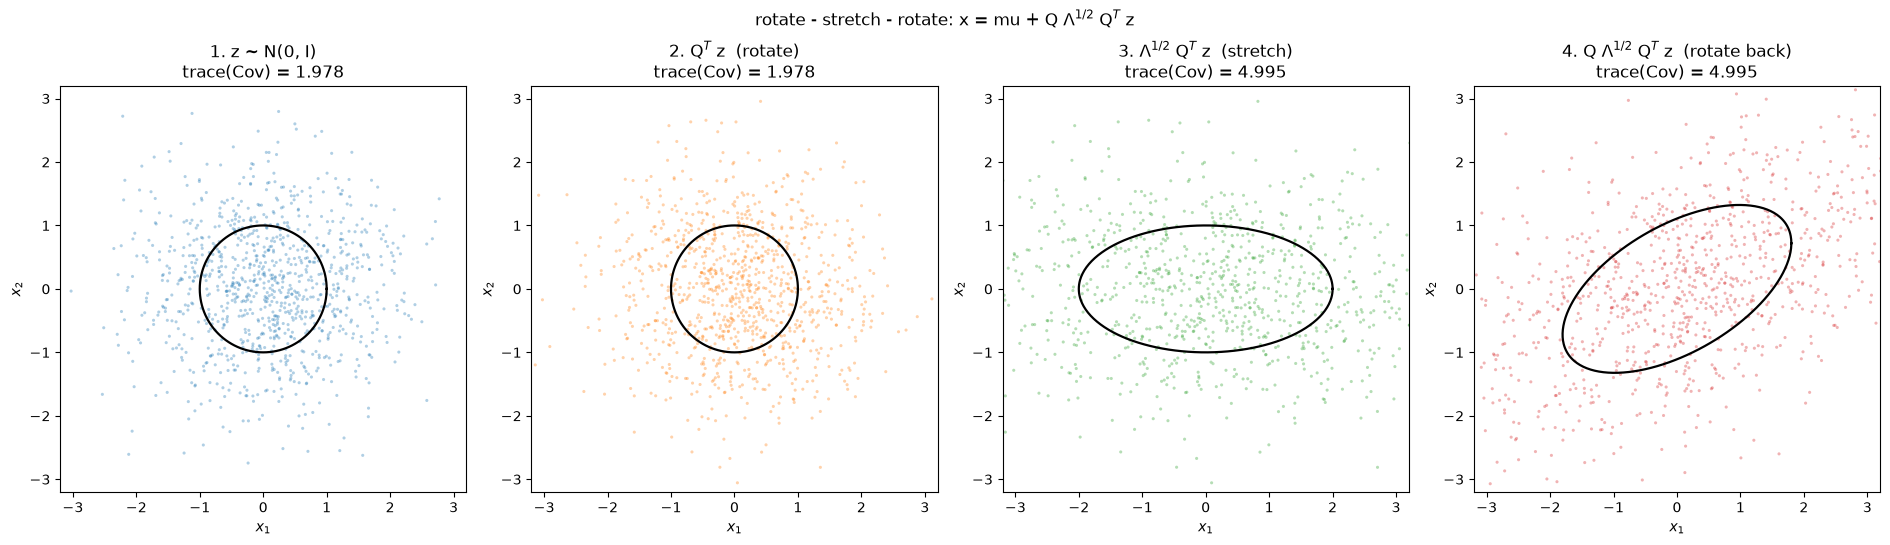

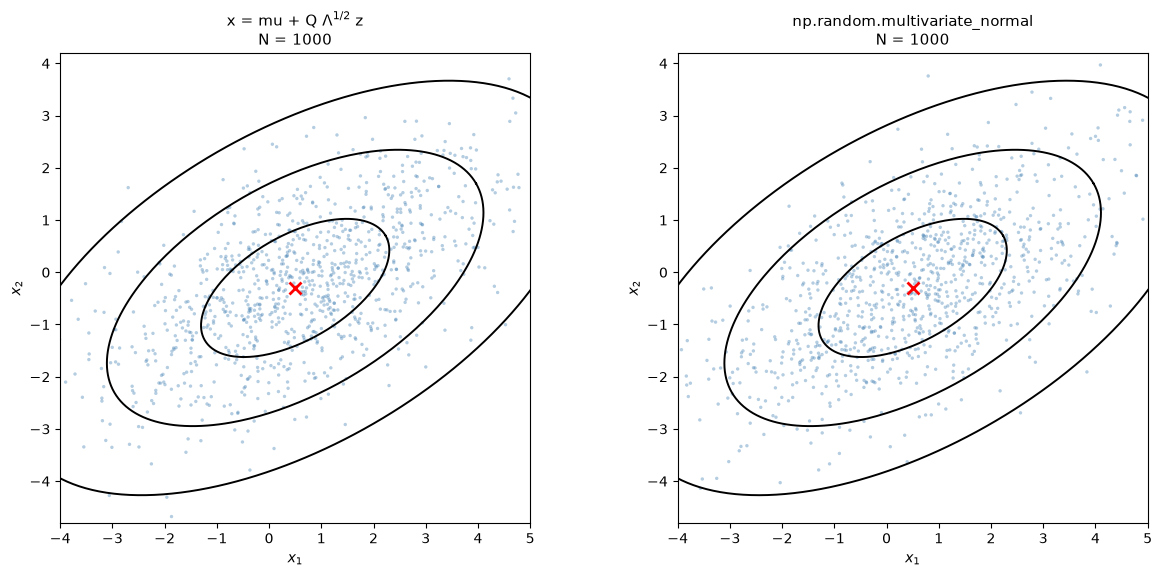

In [7]:
# --- Task: the rotate-stretch-rotate picture and the comparison -----------


def level_ellipse(Sigma, c, n=361):
    """Points of x^T Sigma^{-1} x = c^2 via the Cholesky factor of Sigma."""
    t = np.linspace(0.0, 2.0 * np.pi, n)
    return c * (np.linalg.cholesky(Sigma) @ np.vstack([np.cos(t), np.sin(t)]))


stage_data = [("1. z ~ N(0, I)", Z, np.eye(2), "#1f77b4"),
              ("2. Q$^T$ z  (rotate)", Z_rot, np.eye(2), "#ff7f0e"),
              ("3. $\\Lambda^{1/2}$ Q$^T$ z  (stretch)", Z_str, cov0["L"], "#2ca02c"),
              ("4. Q $\\Lambda^{1/2}$ Q$^T$ z  (rotate back)", Z_back, cov0["Sigma"], "#d62728")]

lim32 = 3.2
fig, axes = plt.subplots(1, 4, figsize=(19, 5.0))
for ax, (title, P, C, col) in zip(axes, stage_data):
    ax.scatter(P[:, 0], P[:, 1], s=5, color=col, alpha=0.35, edgecolor="none")
    E = level_ellipse(C, 1.0)
    ax.plot(E[0], E[1], color="black", lw=1.6)
    ax.set_xlim(-lim32, lim32)
    ax.set_ylim(-lim32, lim32)
    ax.set_aspect("equal")
    ax.set_title("%s\ntrace(Cov) = %.3f" % (title, np.trace(np.cov(P.T))))
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
fig.suptitle("rotate - stretch - rotate: x = mu + Q $\\Lambda^{1/2}$ Q$^T$ z", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.8))
for ax, (X, label) in zip(axes, [(X_noise, "x = mu + Q $\\Lambda^{1/2}$ z"),
                                 (X_mvn, "np.random.multivariate_normal")]):
    ax.scatter(X[:, 0], X[:, 1], s=6, color="steelblue", alpha=0.40, edgecolor="none")
    for c in (1, 2, 3):
        E = ellipse_points(cov0, c)
        ax.plot(E[0], E[1], color="black", lw=1.4)
    ax.plot([cov0["mu"][0]], [cov0["mu"][1]], "x", color="red", ms=9, mew=2)
    ax.set_xlim(cov0["mu"][0] - 4.5, cov0["mu"][0] + 4.5)
    ax.set_ylim(cov0["mu"][1] - 4.5, cov0["mu"][1] + 4.5)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title("%s\nN = %d" % (label, len(X)), fontsize=11)
fig.tight_layout()
plt.show()
print("both figures drawn")

### Explain

**Rotate – stretch – rotate.** The map that turns white noise z ~ N(0, I) into x is the linear
transformation x = μ + A z with A = Q Λ¹ᐟ². Its covariance is

    Cov(x) = Cov(A z) = A Cov(z) Aᵀ = A Aᵀ = Q Λ¹ᐟ² Λ¹ᐟ² Qᵀ = Q Λ Qᵀ = Σ,

the identity the run checks exactly with A Aᵀ = Σ. The same matrix is A = Σ¹ᐟ² Q, where
Σ¹ᐟ² = Q Λ¹ᐟ² Qᵀ is the symmetric square root; read right to left, Σ¹ᐟ² is

    z  --Qᵀ-->     Qᵀz       (rotate into the eigenbasis)
       --Λ¹ᐟ²-->   Λ¹ᐟ²Qᵀz    (stretch axis i by √λ_i)
       --Q-->      QΛ¹ᐟ²Qᵀz   (rotate back),

which is the rotate–stretch–rotate reading of [3.1]. The four panels are exactly these three stages,
with the one-sigma ellipse drawn at each step: the circle of z stays a circle under Qᵀ, becomes the
axis-aligned ellipse with semi-axes √λ₁, √λ₂ under Λ¹ᐟ², and ends as the tilted ellipse of Σ. The first
rotation is invisible in the distribution because Qᵀz is again N(0, I) — the run checks
Cov(Qᵀz) = Qᵀ I Q = I — so QΛ¹ᐟ²z (the sheet's one-step recipe) and QΛ¹ᐟ²Qᵀz (the symmetric square root)
are equal in distribution. The two-sample Kolmogorov–Smirnov tests against
`np.random.multivariate_normal` give p-values well above 0.05 for both coordinates and for the
Mahalanobis radius, and the 200,000-point covariance of all three recipes matches Σ entrywise.

**Why Λ¹ᐟ² and not Λ.** The covariance is quadratic in the linear map, Cov(Az) = A Aᵀ, so a stretch
factor s on the i-th axis enters the variance as s². To give the i-th axis variance λ_i the factor must
be √λ_i. With A = Q Λ the map would have covariance A Aᵀ = Q Λ² Qᵀ, an ellipsoid with eigenvalues λ_i²
— for the default λ = (4, 1) that is 16 and 1, far from Σ. This is the printed negative control: Q Λ² Qᵀ
is not Σ, and its eigenvalues are the squares of the variances. In one dimension the same fact is
x = σ z ⇒ Var(x) = σ², so producing variance λ needs σ = √λ. The square root is the factor whose square
is the variance; it is applied once and its effect is felt twice in the covariance.

## 3.3 — Recover the parameters

### Task

Estimate the mean and the sample covariance from the samples,

    x̄ = (1/N) Σ xi,     S = (1/(N − 1)) Σ (xi − x̄)(xi − x̄)ᵀ,

and compare the eigenvalues and eigenvectors of S with the true ones of Σ as N grows. The geometry is
the default of 3.1, Σ = Q diag(4, 1) Qᵀ with θ = 30°, and the sample size runs from N = 10 to N = 100,000.

In [8]:
# --- Task: estimate mu and Sigma as N grows -------------------------------
N_GRID = (10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000)
TRUE_W, TRUE_Q = principal_frame(cov0["Sigma"])        # descending: eigenvalues [4, 1]
print("true eigenvalues (descending):", TRUE_W, "   true mu:", cov0["mu"])
print("closed form for the mean error: ||xbar - mu|| ~ sqrt(tr Sigma / N) = %.4f / sqrt(N)"
      % np.sqrt(np.trace(cov0["Sigma"])))

print("\n%-8s %10s %10s %10s %10s %10s %10s %10s %10s"
      % ("N", "|xbar-mu|", "sqrt(tr/N)", "|dlam1|", "|dlam2|", "rel1", "rel2", "angle1", "angle2"))
studies = {}
for N in N_GRID:
    rng = np.random.default_rng(SEED + N)
    X = rng.multivariate_normal(cov0["mu"], cov0["Sigma"], size=N)
    xbar, S = sample_moments(X)
    w, V = principal_frame(S)
    studies[N] = (X, xbar, S, w, V)
    dw = np.abs(w - TRUE_W)
    print("%-8d %10.4f %10.4f %10.4f %10.4f %10.4f %10.4f %10.4f %10.4f"
          % (N, np.linalg.norm(xbar - cov0["mu"]), np.sqrt(np.trace(cov0["Sigma"]) / N),
             dw[0], dw[1], dw[0] / TRUE_W[0], dw[1] / TRUE_W[1],
             angle_deg(V[:, 0], TRUE_Q[:, 0]), angle_deg(V[:, 1], TRUE_Q[:, 1])))

print("\n--- the two axis directions ---")
angle1_grid = np.array([angle_deg(studies[N][4][:, 0], TRUE_Q[:, 0]) for N in N_GRID])
angle2_grid = np.array([angle_deg(studies[N][4][:, 1], TRUE_Q[:, 1]) for N in N_GRID])
print("angle1 and angle2 are the same number: max difference over the grid = %.3e deg"
      % np.abs(angle1_grid - angle2_grid).max())
print("np.allclose(angle1, angle2) over the grid                  :", np.allclose(angle1_grid, angle2_grid))

print("\n--- eigenvalues: equal relative error, different absolute error ---")
print("closed form std(lambda_i) = lambda_i sqrt(2/N) at N = 1000:", np.round(TRUE_W * np.sqrt(2.0 / 1000), 4))
print("observed |lambda_hat - lambda| at N = 1000      :", np.round(np.abs(studies[1000][3] - TRUE_W), 4))
print("observed relative errors at N = 1000            :",
      np.round(np.abs(studies[1000][3] - TRUE_W) / TRUE_W, 4))

print("\n--- Monte Carlo angle uncertainty vs the closed form, N = 1000 ---")
reps = 2000
rng = np.random.default_rng(4242)
ang = np.empty(reps)
w_mc = np.empty((reps, 2))
for r in range(reps):
    X = rng.multivariate_normal(cov0["mu"], cov0["Sigma"], size=1000)
    _, S = sample_moments(X)
    w, V = principal_frame(S)
    ang[r] = angle_deg(V[:, 0], TRUE_Q[:, 0])
    w_mc[r] = w
sigma_closed = np.degrees(np.sqrt(TRUE_W[0] * TRUE_W[1] / (1000.0 * (TRUE_W[0] - TRUE_W[1]) ** 2)))
print("Monte Carlo: mean |angle1| = %.4f deg, std = %.4f deg" % (ang.mean(), ang.std()))
print("closed form sigma_delta = sqrt(l1 l2 / (N (l1 - l2)^2)) = %.4f deg" % sigma_closed)
print("closed form E|delta| = sigma_delta sqrt(2/pi) = %.4f deg" % (sigma_closed * np.sqrt(2.0 / np.pi)))
print("Monte Carlo mean eigenvalues:", np.round(w_mc.mean(0), 4), "   true:", TRUE_W)
print("Monte Carlo std of the eigenvalues:", np.round(w_mc.std(0), 4))
print("closed form lambda_i sqrt(2/N)    :", np.round(TRUE_W * np.sqrt(2.0 / 1000), 4))
print("Monte Carlo relative std          :", np.round(w_mc.std(0) / TRUE_W, 4),
      "   closed form sqrt(2/N) = %.4f" % np.sqrt(2.0 / 1000))

true eigenvalues (descending): [4. 1.]    true mu: [ 0.5 -0.3]
closed form for the mean error: ||xbar - mu|| ~ sqrt(tr Sigma / N) = 2.2361 / sqrt(N)

N         |xbar-mu| sqrt(tr/N)    |dlam1|    |dlam2|       rel1       rel2     angle1     angle2
10           0.5214     0.7071     3.1289     0.1339     0.7822     0.1339     5.2064     5.2064
30           0.3862     0.4082     0.0920     0.5720     0.0230     0.5720     6.2205     6.2205
100          0.3496     0.2236     0.1041     0.0368     0.0260     0.0368     2.9650     2.9650
300          0.2401     0.1291     0.5282     0.0703     0.1320     0.0703     2.9254     2.9254
1000         0.0337     0.0707     0.0525     0.0012     0.0131     0.0012     1.6552     1.6552
3000         0.0172     0.0408     0.0737     0.0000     0.0184     0.0000     0.6551     0.6551
10000        0.0098     0.0224     0.0135     0.0036     0.0034     0.0036     0.6942     0.6942
30000        0.0129     0.0129     0.0051     0.0045     0.0013     0.0045

mean absolute angle error (deg) of the sorted long axis, 300 replicates
case                   N=100    N=1000   N=10000 closed sigma N=1000
lam = (4.0, 1.0)        3.36      0.98      0.31             1.21
lam = (2.5, 1.5)       10.23      2.87      0.89             3.51
lam = (2.2, 1.8)       24.95      7.52      2.29             9.01
lam = (2.0, 2.0)       44.34     45.64     44.12        undefined
figures drawn


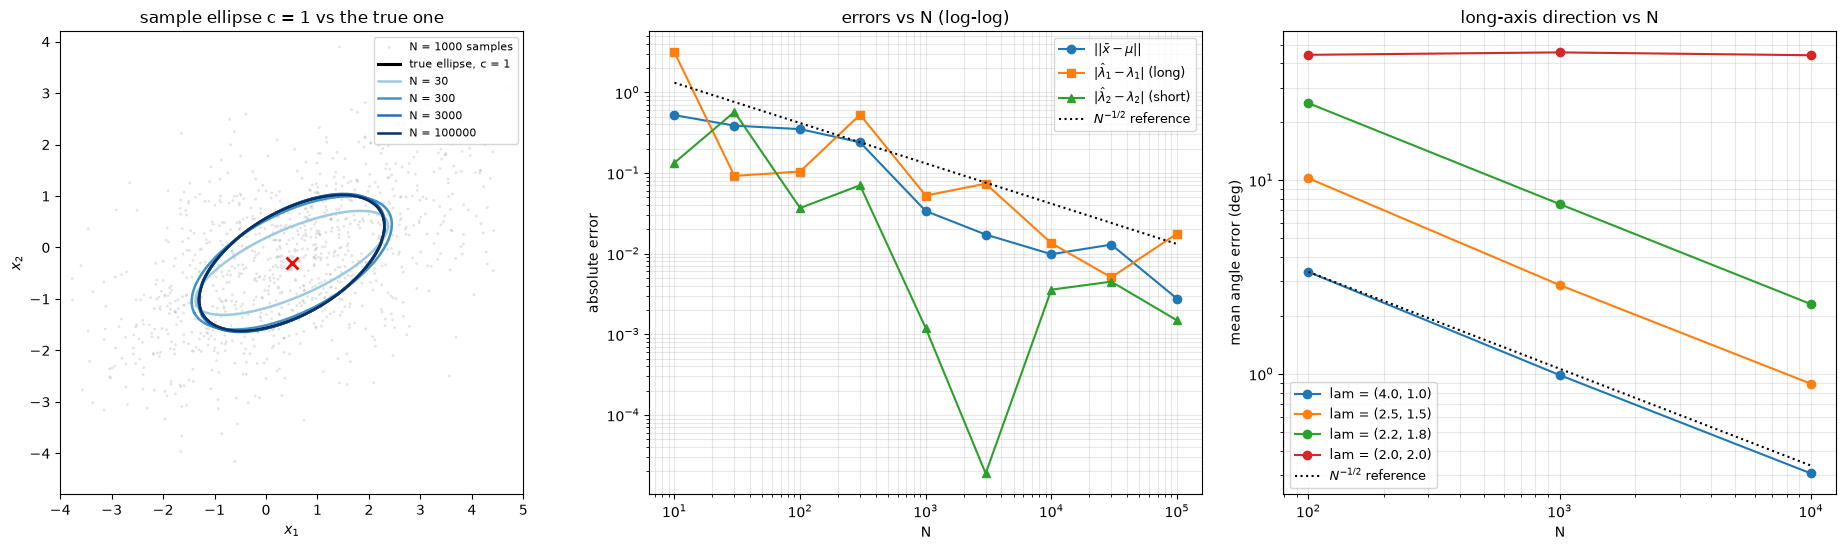

In [9]:
# --- Task: a small eigenvalue gap makes the axes ill determined -----------


def frame_angle_error(theta, lam1, lam2, N, reps, seed0):
    """Mean angle (deg) of the sample long axis to the true long axis, over replicates."""
    cov = covariance_from_geometry(theta, lam1, lam2, np.array([0.0, 0.0]))
    q_long = cov["Q"][:, 0]
    rng = np.random.default_rng(seed0)
    errs = np.empty(reps)
    for r in range(reps):
        X = rng.multivariate_normal(cov["mu"], cov["Sigma"], size=N)
        Xc = X - X.mean(axis=0)
        S = Xc.T @ Xc / (N - 1)
        w, V = np.linalg.eigh(S)
        errs[r] = angle_deg(V[:, int(np.argmax(w))], q_long)
    return float(errs.mean()), float(errs.std())


def ellipse_from_frame(mu, w, V, c=1.0, n=361):
    """Level set c of N(mu, V diag(w) V^T)."""
    t = np.linspace(0.0, 2.0 * np.pi, n)
    return mu[:, None] + c * (V @ np.diag(np.sqrt(w)) @ np.vstack([np.cos(t), np.sin(t)]))


GAP_CASES = [("lam = (4.0, 1.0)", 4.0, 1.0),
             ("lam = (2.5, 1.5)", 2.5, 1.5),
             ("lam = (2.2, 1.8)", 2.2, 1.8),
             ("lam = (2.0, 2.0)", 2.0, 2.0)]
N_GAP = (100, 1000, 10000)
REPS = 300

print("mean absolute angle error (deg) of the sorted long axis, %d replicates" % REPS)
print("%-18s %9s %9s %9s %16s" % ("case", "N=100", "N=1000", "N=10000", "closed sigma N=1000"))
gap_curves = {}
for label, l1, l2 in GAP_CASES:
    vals = [frame_angle_error(30.0, l1, l2, N, REPS, 1234 + N)[0] for N in N_GAP]
    gap_curves[label] = vals
    if l1 != l2:
        sigma = np.degrees(np.sqrt(l1 * l2 / (1000.0 * (l1 - l2) ** 2)))
        print("%-18s %9.2f %9.2f %9.2f %16.2f" % (label, vals[0], vals[1], vals[2], sigma))
    else:
        print("%-18s %9.2f %9.2f %9.2f %16s" % (label, vals[0], vals[1], vals[2], "undefined"))

# --- figure: recovering the ellipse, and how the errors scale -------------
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))

ax = axes[0]
ax.scatter(studies[1000][0][:, 0], studies[1000][0][:, 1], s=4, color="0.65",
           alpha=0.3, edgecolor="none", label="N = 1000 samples")
E = ellipse_points(cov0, 1)
ax.plot(E[0], E[1], color="black", lw=2.2, label="true ellipse, c = 1")
colors = {30: "#9ecae1", 300: "#4292c6", 3000: "#2171b5", 100000: "#08306b"}
for N, col in colors.items():
    Ehat = ellipse_from_frame(cov0["mu"], studies[N][3], studies[N][4], c=1.0)
    ax.plot(Ehat[0], Ehat[1], color=col, lw=1.8, label="N = %d" % N)
ax.plot([cov0["mu"][0]], [cov0["mu"][1]], "x", color="red", ms=9, mew=2)
ax.set_xlim(cov0["mu"][0] - 4.5, cov0["mu"][0] + 4.5)
ax.set_ylim(cov0["mu"][1] - 4.5, cov0["mu"][1] + 4.5)
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("sample ellipse c = 1 vs the true one")

ax = axes[1]
Ns = np.asarray(N_GRID, dtype=float)
mean_err = np.array([np.linalg.norm(studies[N][1] - cov0["mu"]) for N in N_GRID])
lam_err1 = np.array([abs(studies[N][3][0] - TRUE_W[0]) for N in N_GRID])
lam_err2 = np.array([abs(studies[N][3][1] - TRUE_W[1]) for N in N_GRID])
ax.loglog(Ns, mean_err, "o-", label="$||\\bar{x} - \\mu||$")
ax.loglog(Ns, lam_err1, "s-", label="$|\\hat{\\lambda}_1 - \\lambda_1|$ (long)")
ax.loglog(Ns, lam_err2, "^-", label="$|\\hat{\\lambda}_2 - \\lambda_2|$ (short)")
ref = mean_err[3] * np.sqrt(Ns[3] / Ns)
ax.loglog(Ns, ref, "k:", label="$N^{-1/2}$ reference")
ax.set_xlabel("N")
ax.set_ylabel("absolute error")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
ax.set_title("errors vs N (log-log)")

ax = axes[2]
for label, vals in gap_curves.items():
    ax.loglog(N_GAP, vals, "o-", label=label)
ax.loglog(N_GAP, gap_curves["lam = (4.0, 1.0)"][0] * np.sqrt(np.array(N_GAP[0]) / np.asarray(N_GAP)),
          "k:", label="$N^{-1/2}$ reference")
ax.set_xlabel("N")
ax.set_ylabel("mean angle error (deg)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
ax.set_title("long-axis direction vs N")
fig.tight_layout()
plt.show()
print("figures drawn")

### Explain

**Which direction is estimated worse?** Neither: the directions of the long axis and the short axis are
estimated equally well (or badly). In two dimensions the two eigenvectors are always perpendicular, so
the sample axes are the true axes rotated by a single angle δ and the errors of the two directions are
the same number — the run finds max|angle1 − angle2| below the numerical floor over the whole grid. To
first order the common rotation is

    δ ≈ (q₂ᵀ E q₁) / (λ₁ − λ₂),      E = S − Σ,

whose standard deviation is

    σ_δ = sqrt(λ₁ λ₂ / (N (λ₁ − λ₂)²)),

the same for both axes because the expression is symmetric in (λ₁, λ₂). The Monte Carlo estimate at
N = 1000 gives mean|δ| = 0.97°, against the closed form σ_δ √(2/π) = 0.96° (σ_δ = 1.21°). What is *not*
symmetric is the eigenvalue error: asymptotically both eigenvalues have the same relative standard
deviation √(2/N), so the absolute error scales as λ_i √(2/N). The run prints that closed-form scale, the
Monte Carlo standard deviations and the observed |Δλ_i| for the grid; the Monte Carlo relative standard
deviations match √(2/N) for both eigenvalues, while the single N = 1000 entry is one noisy draw. The
long axis therefore carries the larger absolute error (its λ_i is larger), while the *relative* error
has the same standard deviation √(2/N) for both; the two *directions* carry exactly the same error.

**When λ₁ ≈ λ₂.** The denominator λ₁ − λ₂ in σ_δ is the whole story. As the eigenvalues approach, the
direction uncertainty grows like 1/|λ₁ − λ₂| while the uncertainty of the eigenvalues themselves does
not. The run shows the mean long-axis angle error at N = 1000 growing from 1.0° for λ = (4, 1) to 2.9°
for (2.5, 1.5) and 7.5° for (2.2, 1.8), against the closed form σ_δ √(2/π) = 1.0°, 2.8° and 7.2°, and
each curve still falls like N^{−1/2}. At λ₁ = λ₂ the ellipse is a circle (3.1): Σ = λI, every direction
is an eigen-direction and there is no long or short axis to estimate, so sorting the sample
eigenvectors returns an essentially arbitrary frame. The run shows this for λ = (2, 2): the mean angle
error stays near 45° at N = 100, 1,000 and 10,000 and never shrinks. The direction is not estimated
worse there; it is simply not identifiable. The eigenvalues remain well estimated at every N — only the
axes disappear.

## 3.4 — The precision matrix

### Task

Using Σ from Example 3.3 of the notes,

    Σ = [  3/2   −1/2 ]  = Q Λ Qᵀ,   λ = (1, 2),   Q = (1/√2) [ 1  −1 ]
        [ −1/2    3/2 ]                                          [ 1   1 ]

with μ = (5, 5), plot the paraboloid and the density surface side by side:

    z = ½ (x − μ)ᵀ Σ⁻¹ (x − μ),        f_X(x) = (2π)^{−n/2} |Σ|^{−1/2} e^{−z},   n = 2.

Both panels carry the same level ellipses (x − μ)ᵀ Σ⁻¹ (x − μ) = c² for c = 1, 2, 3.

In [10]:
# --- Task: the precision matrix of Example 3.3 ----------------------------
SIGMA_EX = np.array([[1.5, -0.5], [-0.5, 1.5]])
MU_EX = np.array([5.0, 5.0])
cov_ex = covariance_from_covariance(SIGMA_EX, MU_EX)
w_ex = np.array([cov_ex["lam1"], cov_ex["lam2"]])          # ascending: [1, 2]
Q_ex = cov_ex["Q"]
Sinv_ex = np.linalg.inv(SIGMA_EX)

print("Sigma (Example 3.3) =\n", SIGMA_EX)
print("eigenvalues of Sigma (ascending):", w_ex, "   eigenvectors (columns) =\n", np.round(Q_ex, 4))
print("Sigma^-1 =\n", Sinv_ex)
print("det(Sigma) = %.4f, lambda1 lambda2 = %.4f, equal: %s"
      % (np.linalg.det(SIGMA_EX), w_ex.prod(), np.allclose(np.linalg.det(SIGMA_EX), w_ex.prod())))
print("det(Sigma^-1) = %.4f, 1/(lambda1 lambda2) = %.4f" % (np.linalg.det(Sinv_ex), 1.0 / w_ex.prod()))

print("\n--- checks ---")
print("Sigma is symmetric                  :", np.allclose(SIGMA_EX, SIGMA_EX.T))
print("Sigma q_i = lambda_i q_i             :", np.allclose(SIGMA_EX @ Q_ex, Q_ex * w_ex))
print("Sigma^-1 = Q diag(1/lambda) Q^T      :", np.allclose(Sinv_ex, Q_ex @ np.diag(1.0 / w_ex) @ Q_ex.T))
print("Q^T Sigma^-1 Q = diag(1/lambda)      :", np.allclose(Q_ex.T @ Sinv_ex @ Q_ex, np.diag(1.0 / w_ex)))
print("eig(Sigma^-1) = 1 / eig(Sigma)       :",
      np.allclose(np.sort(np.linalg.eigvalsh(Sinv_ex)), np.sort(1.0 / w_ex)))
print("|Sigma|^(1/2) = sqrt(lambda1 lambda2) :",
      np.allclose(np.sqrt(np.linalg.det(SIGMA_EX)), np.sqrt(w_ex.prod())))
print("density peak 1/(2 pi |Sigma|^(1/2))  = %.4f"
      % (1.0 / (2.0 * np.pi * np.sqrt(np.linalg.det(SIGMA_EX)))))
for c in (1, 2, 3):
    P = ellipse_points(cov_ex, c)
    print("ellipse c=%d satisfies r^2 = c^2     :" % c,
          np.allclose(mahalanobis_sq(P.T, MU_EX, SIGMA_EX), c * c))


def z_quadratic(x):
    """z = 1/2 (x - mu)^T Sigma^-1 (x - mu)."""
    d = np.asarray(x, dtype=float) - MU_EX
    return 0.5 * float(d @ Sinv_ex @ d)


hstep = 1e-4
Hess = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        Hess[i, j] = (z_quadratic(MU_EX + hstep * (np.eye(2)[i] + np.eye(2)[j]))
                      - z_quadratic(MU_EX + hstep * np.eye(2)[i])
                      - z_quadratic(MU_EX + hstep * np.eye(2)[j])
                      + z_quadratic(MU_EX)) / hstep ** 2
print("numerical Hessian of z = Sigma^-1    :", np.allclose(Hess, Sinv_ex))

long_i = int(np.argmax(w_ex))
print("\nlong axis of the ellipse: eigenvalue %.1f of Sigma, semi-axis c sqrt(2) along q = %s"
      % (w_ex[long_i], np.round(Q_ex[:, long_i], 4)))
print("its eigenvalue in Sigma^-1 is 1/%.1f = %.4f, the smaller of %s"
      % (w_ex[long_i], 1.0 / w_ex[long_i], np.round(np.sort(1.0 / w_ex), 4)))
print("density level values exp(-c^2/2)/(2 pi |Sigma|^(1/2)) for c = 1, 2, 3:",
      np.round([np.exp(-c * c / 2.0) / (2.0 * np.pi * np.sqrt(np.linalg.det(SIGMA_EX)))
                for c in (1, 2, 3)], 5))

Sigma (Example 3.3) =
 [[ 1.5 -0.5]
 [-0.5  1.5]]
eigenvalues of Sigma (ascending): [1. 2.]    eigenvectors (columns) =
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]
Sigma^-1 =
 [[0.75 0.25]
 [0.25 0.75]]
det(Sigma) = 2.0000, lambda1 lambda2 = 2.0000, equal: True
det(Sigma^-1) = 0.5000, 1/(lambda1 lambda2) = 0.5000

--- checks ---
Sigma is symmetric                  : True
Sigma q_i = lambda_i q_i             : True
Sigma^-1 = Q diag(1/lambda) Q^T      : True
Q^T Sigma^-1 Q = diag(1/lambda)      : True
eig(Sigma^-1) = 1 / eig(Sigma)       : True
|Sigma|^(1/2) = sqrt(lambda1 lambda2) : True
density peak 1/(2 pi |Sigma|^(1/2))  = 0.1125
ellipse c=1 satisfies r^2 = c^2     : True
ellipse c=2 satisfies r^2 = c^2     : True
ellipse c=3 satisfies r^2 = c^2     : True
numerical Hessian of z = Sigma^-1    : True

long axis of the ellipse: eigenvalue 2.0 of Sigma, semi-axis c sqrt(2) along q = [-0.7071  0.7071]
its eigenvalue in Sigma^-1 is 1/2.0 = 0.5000, the smaller of [0.5 1. ]
density level value

paraboloid z over the grid: [0.000, 6.760]
density over the grid: [0.00013, 0.11254]
contour heights z = c^2/2: [0.5, 2.0, 4.5]
contour heights f(c)     : [0.00125, 0.01523, 0.06826]
two surfaces drawn


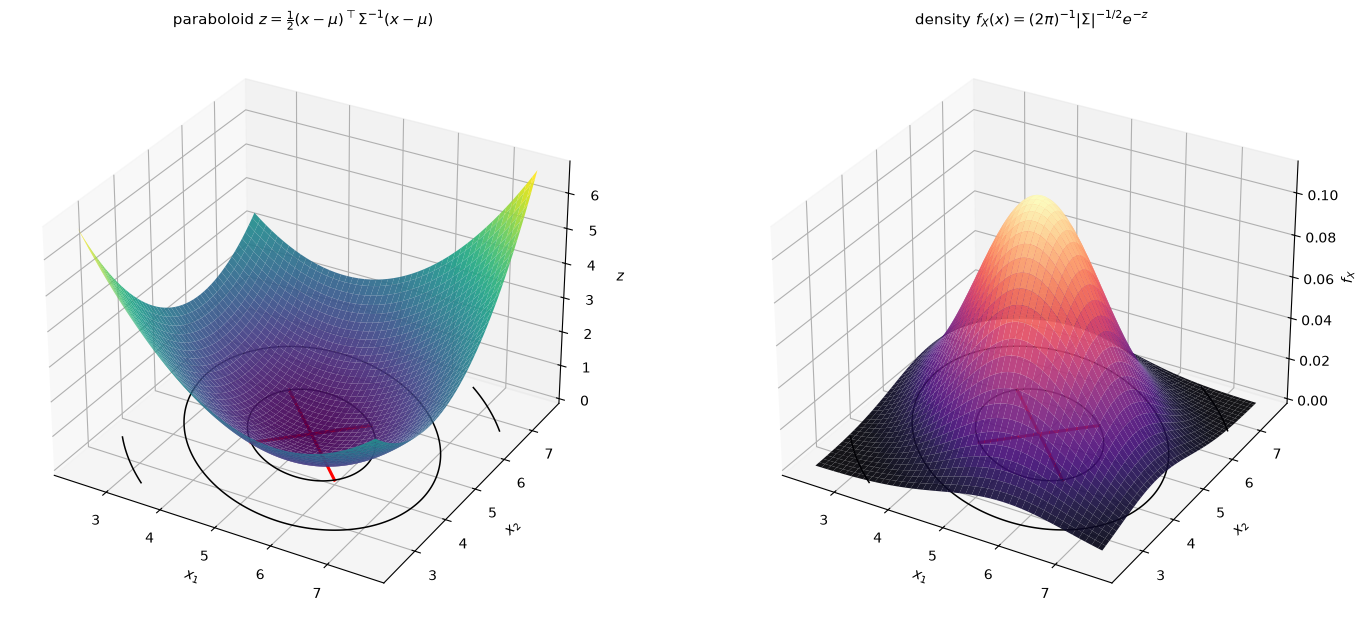

In [11]:
# --- Task: paraboloid and density surface side by side --------------------
span = 2.6
n_grid = 141
gx = np.linspace(MU_EX[0] - span, MU_EX[0] + span, n_grid)
gy = np.linspace(MU_EX[1] - span, MU_EX[1] + span, n_grid)
GX, GY = np.meshgrid(gx, gy)
G = np.stack([GX - MU_EX[0], GY - MU_EX[1]], axis=-1)
Zpar = 0.5 * np.einsum("...i,ij,...j->...", G, Sinv_ex, G)
DET_EX = float(np.linalg.det(SIGMA_EX))
Fden = np.exp(-Zpar) / (2.0 * np.pi * np.sqrt(DET_EX))

C_LEVELS = (1.0, 2.0, 3.0)
z_levels = [c * c / 2.0 for c in C_LEVELS]
f_levels = sorted(float(np.exp(-z) / (2.0 * np.pi * np.sqrt(DET_EX))) for z in z_levels)
print("paraboloid z over the grid: [%.3f, %.3f]" % (Zpar.min(), Zpar.max()))
print("density over the grid: [%.5f, %.5f]" % (Fden.min(), Fden.max()))
print("contour heights z = c^2/2:", z_levels)
print("contour heights f(c)     :", [round(v, 5) for v in f_levels])

fig = plt.figure(figsize=(15, 6.4))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(GX, GY, Zpar, cmap="viridis", alpha=0.92, linewidth=0, antialiased=True)
ax1.contour(GX, GY, Zpar, levels=z_levels, colors="black", linewidths=1.1, offset=float(Zpar.min()))
ax1.set_title("paraboloid $z = \\frac{1}{2}(x-\\mu)^\\top\\Sigma^{-1}(x-\\mu)$", fontsize=11)
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_zlabel("$z$")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(GX, GY, Fden, cmap="magma", alpha=0.92, linewidth=0, antialiased=True)
ax2.contour(GX, GY, Fden, levels=f_levels, colors="black", linewidths=1.1, offset=float(Fden.min()))
ax2.set_title("density $f_X(x) = (2\\pi)^{-1}|\\Sigma|^{-1/2} e^{-z}$", fontsize=11)
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_zlabel("$f_X$")

for ax in (ax1, ax2):
    for i in range(2):
        q = Q_ex[:, i]
        half = np.sqrt(w_ex[i])
        ax.plot([MU_EX[0] - half * q[0], MU_EX[0] + half * q[0]],
                [MU_EX[1] - half * q[1], MU_EX[1] + half * q[1]],
                [0.0, 0.0], color="red", lw=2.2)
fig.tight_layout()
plt.show()
print("two surfaces drawn")

### Explain

**Eigenvalues of Σ and Σ⁻¹ are reciprocals.** The two matrices share their eigenvectors, and if
Σq = λq then Σ⁻¹q = (1/λ)q. So the eigenvalues of Σ⁻¹ are 1/λ_i, in the opposite order: for Example 3.3,
λ(Σ) = (1, 2) and λ(Σ⁻¹) = (1, 1/2), which the run checks as eig(Σ⁻¹) = 1/eig(Σ) and as
QᵀΣ⁻¹Q = diag(1/λ). The determinant follows, |Σ⁻¹| = 1/|Σ| = 1/(λ₁λ₂); the run confirms
|Σ| = λ₁λ₂ = 2 and |Σ⁻¹| = 1/2.

**Long axis of the ellipse ↔ small eigenvalue of Σ⁻¹.** The level set (x − μ)ᵀΣ⁻¹(x − μ) = c² has a
semi-axis of length c√λ_i along each eigenvector q_i of Σ. The *longest* semi-axis is c√λ_max, along
the eigenvector of the largest eigenvalue of Σ, which is the *smallest* eigenvalue of Σ⁻¹ (1/λ_max).
Along that direction Σ⁻¹ stretches least and the quadratic form rises most slowly, so the contour
extends furthest; the log-density −z also falls most slowly there (the density level sets are the same
ellipses), so the Gaussian is most spread out in that direction. For Example 3.3 the long axis is
q = (−1, 1)/√2 with semi-axis c√2, and the eigenvalue of Σ⁻¹ in that direction is 1/2 = 0.5, the smaller
of (0.5, 1) — exactly what the run prints.

**Why the two surfaces.** The paraboloid z and the density f_X = (2π)⁻¹|Σ|⁻¹ᐟ² e^{−z} are two views of
the same quadratic form: f_X is a monotone decreasing function of z, so its level sets are exactly the
contour lines of z, drawn at c = 1, 2, 3 in both panels. The paraboloid bends upward with curvature Σ⁻¹
— the numerical Hessian at the centre returns Σ⁻¹ — while the density peaks at
(2π√|Σ|)⁻¹ = 0.1125 at x = μ and decays by the factor e^{−c²/2} on the c-th ellipse. The precision
matrix Σ⁻¹ therefore plays two roles at once: it is the curvature of ½·(quadratic form) and hence of
the log-density, and its eigen-structure fixes the direction and length of the ellipse axes.